# OPTIMIZED: Adversarially Robust LLM-Based Phishing Detection

**Team:** Antigravity  
**Optimizations Applied:**
- Reduced dataset size for faster training (1000 samples per class instead of 5000)
- Fewer training epochs (2 instead of 3) with early stopping
- Smaller batch sizes to reduce memory usage
- Progress bars for long operations
- Cached model downloads
- Optional label cleaning (can be skipped for speed)
- Parallel processing where possible
- Smaller evaluation batches

**Expected speed improvement: 3-5x faster**

**M4 update:** Step 10 now evaluates all five configurations. A standalone M4 evaluation/export cell is near the end, before Done. M4 results require execution.


## Step 1: Install Dependencies + GPU Check

In [1]:
# Install packages
!pip install -q transformers torch scikit-learn pandas
!pip install -q sentence-transformers faiss-cpu
!pip install -q accelerate sentencepiece requests datasets huggingface_hub
!pip install -q fastapi uvicorn pyngrok gradio
!pip install -q tqdm  # Progress bars

import torch
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('\n' + '='*50)
print(f'DEVICE: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print('✓ GPU acceleration enabled - training will be fast')
else:
    print('⚠ NO GPU detected - training will be SLOW')
    print('   Enable GPU: Runtime → Change runtime type → T4 GPU')
print('='*50 + '\n')


DEVICE: cuda
GPU: Tesla T4
✓ GPU acceleration enabled - training will be fast



## Step 2: Configuration (EDIT THIS FOR SPEED TESTING)

In [2]:
# ============ OPTIMIZATION SETTINGS ============
# Adjust these to trade speed vs accuracy

# Dataset size
MAX_PER_CLASS = 1000      # Reduced from 5000 → 5x faster
POOL_PER_CLASS = 2000     # Reduced from 10000

# Training
TRAIN_EPOCHS = 2          # Reduced from 3
BATCH_SIZE = 8            # Reduced from 16 to save memory
LEARNING_RATE = 3e-5

# Label cleaning
CLEAN_LABELS = False      # Set False to skip expensive cross-validation
NOISE_THRESHOLD = 0.10

# Other settings
SEED = 42
SUSPICIOUS_TLDS = {'.xyz','.top','.tk','.cf','.ga','.gq','.buzz','.icu','.click','.link','.cc','.live','.support','.info','.club'}
POPULAR_BRANDS = ['google','paypal','github','microsoft','apple','amazon','netflix','chase','bankofamerica','wellsfargo','facebook','instagram','twitter','linkedin','youtube','dropbox','zoom','slack','adobe','ebay','walmart','binance','coinbase','whatsapp','telegram','spotify','steam','roblox','reddit','tiktok','yahoo','pinterest','snapchat','discord']

LEGIT_DOMAINS = {
    'google.com','google.co.in','google.co.uk','google.ca','google.de','accounts.google.com','mail.google.com',
    'paypal.com','github.com','microsoft.com','login.microsoftonline.com','outlook.com','apple.com','icloud.com',
    'amazon.com','amazon.in','amazon.co.uk','aws.amazon.com','netflix.com','chase.com','bankofamerica.com',
    'wellsfargo.com','facebook.com','instagram.com','twitter.com','x.com','linkedin.com','youtube.com',
    'reddit.com','wikipedia.org','stackoverflow.com','dropbox.com','zoom.us','slack.com'
}

print('Configuration loaded')
print(f'  Dataset: {MAX_PER_CLASS} samples per class')
print(f'  Training: {TRAIN_EPOCHS} epochs, batch size {BATCH_SIZE}')
print(f'  Label cleaning: {"enabled" if CLEAN_LABELS else "DISABLED (faster)"}')

Configuration loaded
  Dataset: 1000 samples per class
  Training: 2 epochs, batch size 8
  Label cleaning: DISABLED (faster)


## Step 3: Dataset Loading with Progress

In [3]:
import math
import re
import random
import urllib.parse
import pandas as pd
import numpy as np
import requests
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

random.seed(SEED)
np.random.seed(SEED)

# Fallback corpus (if downloads fail)
PHISHING_URLS_BUILTIN = [
    'http://paypal.com.account-verify.xyz/signin',
    'http://paypa1.com/login',
    'http://microsoft-login-secure.top/office365',
    'http://google.com.phish-site.xyz/accounts',
    'http://g00gle.com/mail/signin',
    'http://chase-secure.account-alert.xyz/login',
    'http://amazon.com.checkout-verify.xyz/signin',
    'http://amaz0n.com/login',
    'http://apple.com.phish.xyz/appleid',
    'http://netflix.account-hold.xyz/verify',
]

LEGIT_URLS_BUILTIN = [
    'https://www.google.com',
    'https://mail.google.com/mail/u/0/',
    'https://www.paypal.com/signin',
    'https://github.com/login',
    'https://www.microsoft.com/en-us/microsoft-365',
    'https://www.apple.com/shop/buy-iphone',
    'https://www.amazon.com/cart',
    'https://www.netflix.com/browse',
    'https://www.facebook.com/login',
    'https://www.instagram.com/accounts/login',
]

def prep(url):
    """Remove scheme from URL for model input"""
    return re.sub(r'^[a-zA-Z][a-zA-Z0-9+.\-]*://', '', str(url).strip())

def canon(url):
    """Normalize URL for duplicate detection"""
    u = re.sub(r'^www\d?\.', '', prep(url), flags=re.I)
    return u.rstrip('/').lower()

print('Loading datasets from Hugging Face...')
print('This may take 2-5 minutes on first run (cached afterwards)\n')

def load_kmack():
    try:
        from datasets import load_dataset
        print('[1/2] Loading kmack/Phishing_urls...', end=' ')
        ds = load_dataset('kmack/Phishing_urls', trust_remote_code=False)
        df = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
        col = 'text' if 'text' in df.columns else 'url'
        df = df.rename(columns={col: 'url'})[['url', 'label']]
        df['source'] = 'kmack'
        print(f'✓ {len(df):,} rows')
        return df
    except Exception as e:
        print(f'✗ Failed: {str(e)[:100]}')
        return None

def load_ealvaradob():
    try:
        print('[2/2] Loading ealvaradob/phishing-dataset...', end=' ')
        try:
            from huggingface_hub import hf_hub_download
            path = hf_hub_download('ealvaradob/phishing-dataset', 'urls.json', repo_type='dataset')
            df = pd.read_json(path)
        except Exception:
            r = requests.get('https://huggingface.co/datasets/ealvaradob/phishing-dataset/resolve/main/urls.json', timeout=300)
            r.raise_for_status()
            df = pd.DataFrame(r.json())
        col = 'text' if 'text' in df.columns else 'url'
        df = df.rename(columns={col: 'url'})[['url', 'label']]
        df['source'] = 'ealvaradob'
        print(f'✓ {len(df):,} rows')
        return df
    except Exception as e:
        print(f'✗ Failed: {str(e)[:100]}')
        return None

frames = [f for f in (load_kmack(), load_ealvaradob()) if f is not None]

if frames:
    print('\nMerging and deduplicating...', end=' ')
    df = pd.concat(frames, ignore_index=True)
    df['label'] = pd.to_numeric(df['label'], errors='coerce')
    df = df[df['label'].isin([0, 1])].copy()
    df['label'] = df['label'].astype(int)
    df['url'] = df['url'].astype(str).str.strip()

    # Clean
    df = df[~df['url'].str.contains(r'\s', regex=True) & df['url'].str.len().between(4, 250)].copy()
    df['key'] = df['url'].map(canon)
    nlab = df.groupby('key')['label'].nunique()
    conflict = set(nlab[nlab > 1].index)
    df = df[~df['key'].isin(conflict)].drop_duplicates(subset='key').copy()
    df['url'] = df['url'].map(prep)

    # Sample
    parts = []
    for lbl in (0, 1):
        sub = df[df['label'] == lbl]
        parts.append(sub.sample(min(len(sub), POOL_PER_CLASS), random_state=SEED))
    df_all = pd.concat(parts, ignore_index=True)[['url', 'label', 'source']]
    print(f'✓ {len(df_all):,} URLs')
    data_source = 'external'
else:
    print('\n⚠ All downloads failed - using built-in corpus')
    df_all = pd.DataFrame(
        [(prep(u), 1, 'builtin') for u in PHISHING_URLS_BUILTIN] +
        [(prep(u), 0, 'builtin') for u in LEGIT_URLS_BUILTIN],
        columns=['url', 'label', 'source']
    )
    data_source = 'builtin'

print(f'\n📊 Dataset: {len(df_all):,} URLs | Phishing: {int(df_all.label.sum()):,} | Legit: {int((df_all.label == 0).sum()):,}')
print(f'Source: {data_source}')
print(df_all.sample(5, random_state=SEED))

Loading datasets from Hugging Face...
This may take 2-5 minutes on first run (cached afterwards)

[1/2] Loading kmack/Phishing_urls... 

README.md:   0%|          | 0.00/518 [00:00<?, ?B/s]

data/train-00000-of-00001-d8afc95a165ea8(…): reconstructing file:   0%|          |  0.00B / 25.4MB            

data/train-00000-of-00001-d8afc95a165ea8(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-4d6cbda5297196e(…): reconstructing file:   0%|          |  0.00B / 3.18MB            

data/test-00000-of-00001-4d6cbda5297196e(…): downloading bytes:           |  0.00B            

... (5 outputs left out)

✓ 708,820 rows
[2/2] Loading ealvaradob/phishing-dataset... 

urls.json: reconstructing file:   0%|          |  0.00B / 73.2MB            

urls.json: downloading bytes:           |  0.00B            

✓ 835,697 rows

Merging and deduplicating... ✓ 4,000 URLs

📊 Dataset: 4,000 URLs | Phishing: 2,000 | Legit: 2,000
Source: external
                                                    url  label      source
555   courierpress.com/news/2009/oct/05/strouses-dep...      0       kmack
3491                                        yksnfm.ink/      1  ealvaradob
527                   atwater.org/index.cfm?page=284210      0  ealvaradob
3925                        goubaorun.com/ap/signin.php      1       kmack
2989           www.smbo-ccrd.com.mrd5e8z2ett0s134.shop/      1  ealvaradob


## Step 4: Feature Extraction

In [4]:
# Homoglyph mappings
HOMOGLYPH_MAP = {
    'a': ['\u0430', '4'],
    'e': ['\u0435', '3'],
    'o': ['\u043e', '0'],
    'p': ['\u0440'],
    'c': ['\u0441'],
    'i': ['1', 'l', '\u0456'],
    'l': ['1', 'I'],
    's': ['5'],
    't': ['7']
}

HOMOGLYPH_REVERSE = {
    '\u0430':'a','4':'a','@':'a','\u0435':'e','3':'e',
    '\u043e':'o','0':'o','\u0440':'p','\u0441':'c',
    '\u0456':'i','1':'i','5':'s','$':'s','7':'t'
}

def shannon_entropy(text):
    if not text:
        return 0.0
    freq = {}
    for ch in text:
        freq[ch] = freq.get(ch, 0) + 1
    n = len(text)
    return round(-sum((v/n) * math.log2(v/n) for v in freq.values()), 4)

def normalize_url(url):
    u = str(url).strip()
    if not u:
        return '', urllib.parse.urlparse('')
    if not re.match(r'^[a-zA-Z][a-zA-Z0-9+\-.]*://', u):
        u = 'http://' + u
    try:
        return u, urllib.parse.urlparse(u)
    except ValueError:
        return u, urllib.parse.urlparse('http://invalid.invalid')

def is_legit_domain(hostname):
    h = (hostname or '').lower().strip().split(':')[0]
    if not h or any(ord(c) > 127 for c in h):
        return False
    return any(h == d or h.endswith('.' + d) for d in LEGIT_DOMAINS)

def levenshtein(s1, s2):
    """Damerau-Levenshtein distance"""
    d = [[0] * (len(s2) + 1) for _ in range(len(s1) + 1)]
    for i in range(len(s1) + 1):
        d[i][0] = i
    for j in range(len(s2) + 1):
        d[0][j] = j
    for i in range(1, len(s1) + 1):
        for j in range(1, len(s2) + 1):
            cost = 0 if s1[i-1] == s2[j-1] else 1
            d[i][j] = min(d[i-1][j] + 1, d[i][j-1] + 1, d[i-1][j-1] + cost)
            if i > 1 and j > 1 and s1[i-1] == s2[j-2] and s1[i-2] == s2[j-1]:
                d[i][j] = min(d[i][j], d[i-2][j-2] + 1)
    return d[-1][-1]

def detect_evasion(url):
    """Detect adversarial evasion techniques"""
    norm, parsed = normalize_url(url)
    host = (parsed.hostname or '').lower()

    if is_legit_domain(host):
        return {
            'has_evasion': False,
            'is_official_legit': True,
            'techniques': [],
            'primary_technique': 'none',
            'details': [f'official domain: {host}']
        }

    found_techs = []
    found_details = []
    is_ip = bool(re.match(r'^(?:\d{1,3}\.){3}\d{1,3}$', host))

    if not is_ip:
        parts = host.split('.')
        # Check for homoglyphs and typosquatting
        for label in parts:
            for brand in POPULAR_BRANDS:
                if brand in label and len(label) >= 5:
                    if levenshtein(label, brand) <= 1:
                        found_techs.append('homoglyph')
                        found_details.append(f"suspicious label '{label}' similar to '{brand}'")
                        break

    return {
        'has_evasion': len(found_techs) > 0,
        'is_official_legit': False,
        'techniques': found_techs,
        'primary_technique': found_techs[0] if found_techs else 'none',
        'details': found_details
    }

def get_url_features(url):
    """Extract all URL features"""
    norm, parsed = normalize_url(url)
    host = parsed.hostname or ''

    evasion = detect_evasion(norm)
    is_ip = bool(re.match(r'^(?:\d{1,3}\.){3}\d{1,3}$', host))
    tld_match = re.search(r'(\.[a-zA-Z0-9\-]+)$', host)
    tld = tld_match.group(1).lower() if (tld_match and not is_ip) else ''
    n_subdomains = max(0, len(host.split('.')) - 2) if not is_ip else 0
    sensitive = ['login','signin','verify','account','update','banking','secure','auth','confirm','wallet','password']
    kw_found = [k for k in sensitive if k in norm.lower()]

    return {
        'url': norm,
        'hostname': host,
        'url_length': len(norm),
        'entropy': shannon_entropy(norm),
        'has_ip_hostname': is_ip,
        'tld': tld,
        'is_suspicious_tld': tld in SUSPICIOUS_TLDS,
        'num_subdomains': n_subdomains,
        'detected_sensitive_keywords': kw_found,
        'adversarial_evasion': evasion
    }

print('Feature extraction functions loaded ✓')
# Test
test_url = 'http://paypa1.com/signin'
features = get_url_features(test_url)
print(f'\nTest: {test_url}')
print(f'  Evasion detected: {features["adversarial_evasion"]["has_evasion"]}')
print(f'  Suspicious TLD: {features["is_suspicious_tld"]}')

Feature extraction functions loaded ✓

Test: http://paypa1.com/signin
  Evasion detected: False
  Suspicious TLD: False


## Step 5: Label Cleaning (Optional - Can Skip)

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

pool = df_all.copy().reset_index(drop=True)

if data_source == 'external' and CLEAN_LABELS:
    print('Running label cleaning (this takes 1-2 minutes)...')
    n_before = len(pool)

    # Rule 1: Remove phishing labels on official domains
    hosts = pool['url'].map(lambda u: normalize_url(u)[1].hostname or '')
    rule_bad = (pool['label'] == 1) & hosts.map(is_legit_domain)
    print(f'  Rule 1: {int(rule_bad.sum())} phishing-labeled official domains removed')
    pool = pool[~rule_bad].reset_index(drop=True)

    # Rule 2: Confident learning filter
    print('  Rule 2: Running cross-validation...', end=' ')
    vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=50000, sublinear_tf=True)
    Xp = vec.fit_transform(pool['url'])
    yp = pool['label'].values
    proba = cross_val_predict(LogisticRegression(max_iter=300), Xp, yp, cv=5, method='predict_proba', n_jobs=-1)
    p_own = proba[np.arange(len(yp)), yp]
    suspect = p_own < NOISE_THRESHOLD
    print(f'✓ {int(suspect.sum())} noisy labels detected')
    pool = pool[~suspect].reset_index(drop=True)
    print(f'  Kept {len(pool):,} of {n_before:,} URLs ({len(pool)/n_before:.0%})')
elif data_source == 'external':
    print('⚡ Label cleaning SKIPPED for speed - using raw labels')

# Balance and split
n_per = int(min(MAX_PER_CLASS, pool['label'].value_counts().min()))
df_raw = pd.concat([pool[pool['label'] == l].sample(n_per, random_state=SEED) for l in (0, 1)], ignore_index=True)
df_raw = df_raw.drop_duplicates(subset=['url']).sample(frac=1, random_state=SEED).reset_index(drop=True)

train_df, temp = train_test_split(df_raw, test_size=0.30, stratify=df_raw['label'], random_state=SEED)
val_df, test_df = train_test_split(temp, test_size=0.50, stratify=temp['label'], random_state=SEED)

print(f'\n📊 Final splits:')
print(f'  Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')
print(f'  No leakage: {len(set(train_df.url) & set(test_df.url)) == 0} ✓')

⚡ Label cleaning SKIPPED for speed - using raw labels

📊 Final splits:
  Train: 1,400 | Val: 300 | Test: 300
  No leakage: True ✓


## Step 6: Adversarial Mutations

In [6]:
def _is_ip(host):
    return bool(re.match(r'^(?:\d{1,3}\.){3}\d{1,3}$', host or ''))

def with_host(p, new_host):
    prefix = p.netloc.rpartition('@')[0]
    prefix = prefix + '@' if prefix else ''
    port = re.search(r':(\d+)$', p.netloc)
    netloc = prefix + new_host + (port.group(0) if port else '')
    return urllib.parse.urlunparse((p.scheme, netloc, p.path, p.params, p.query, p.fragment))

def mutate_homoglyph(url):
    _, p = normalize_url(url)
    host = p.hostname or ''
    if not host or _is_ip(host):
        return url
    chars = list(host)
    tld_start = host.rfind('.')
    swappable = [i for i, c in enumerate(chars) if c.lower() in HOMOGLYPH_MAP and i < tld_start]
    if not swappable:
        return url
    idx = random.choice(swappable)
    chars[idx] = random.choice(HOMOGLYPH_MAP[chars[idx].lower()])
    return with_host(p, ''.join(chars))

def mutate_subdomain(url):
    _, p = normalize_url(url)
    host = p.hostname or 'portal.com'
    brand = random.choice(['paypal.com', 'microsoft.com', 'apple.com'])
    new_host = host if host.startswith(brand + '.') else f'{brand}.{host}'
    return with_host(p, new_host)

def mutate_padding(url):
    _, p = normalize_url(url)
    junk = 'utm_source=security&auth_token=verified'
    new_q = f'{p.query}&{junk}' if p.query else junk
    return urllib.parse.urlunparse((p.scheme, p.netloc, p.path or '/', p.params, new_q, p.fragment))

def mutate_encoding(url):
    _, p = normalize_url(url)
    path = p.path if len(p.path) > 1 else '/login'
    encoded = [f'%{ord(c):02x}' if (c.isascii() and c.isalnum() and random.random() < 0.3) else c for c in path]
    return urllib.parse.urlunparse((p.scheme, p.netloc, ''.join(encoded), p.params, p.query, p.fragment))

def mutate_typosquat(url):
    _, p = normalize_url(url)
    host = p.hostname or ''
    parts = host.split('.')
    if _is_ip(host) or len(parts) < 2 or len(parts[-2]) < 4:
        return url
    chars = list(parts[-2])
    cand = [i for i in range(len(chars) - 1) if chars[i] != chars[i + 1]]
    if not cand:
        return url
    i = random.choice(cand)
    chars[i], chars[i + 1] = chars[i + 1], chars[i]
    parts[-2] = ''.join(chars)
    return with_host(p, '.'.join(parts))

MUTATIONS = {
    'homoglyph': mutate_homoglyph,
    'subdomain': mutate_subdomain,
    'padding': mutate_padding,
    'encoding': mutate_encoding,
    'typosquatting': mutate_typosquat
}

def perturb(url, technique='random'):
    order = list(MUTATIONS.keys())
    random.shuffle(order)
    if technique in MUTATIONS:
        order = [technique] + [t for t in order if t != technique]
    for t in order:
        out = MUTATIONS[t](url)
        if out != url:
            return out, t
    return url, 'none'

def all_mutations(url):
    return {t: f(url) for t, f in MUTATIONS.items()}

# Build adversarial test set
print('Creating adversarial test set...', end=' ')
adv_records = []
for _, row in test_df.iterrows():
    u, lbl = row['url'], row['label']
    if lbl == 1:
        pu, tech = perturb(u)
        adv_records.append({'url': pu, 'original_url': u, 'label': 1, 'technique': tech})
    else:
        adv_records.append({'url': u, 'original_url': u, 'label': 0, 'technique': 'clean'})
adv_test_df = pd.DataFrame(adv_records)
print(f'✓ {len(adv_test_df)} samples')

# Augmented training
print('Creating augmented training set...', end=' ')
aug_rows = []
for _, row in train_df[train_df.label == 1].iterrows():
    pu, _t = perturb(row.url)
    aug_rows.append({'url': pu, 'label': 1})
for _, row in train_df[train_df.label == 0].sample(frac=0.3, random_state=SEED).iterrows():
    pu, _t = perturb(row.url, random.choice(['padding', 'encoding']))
    aug_rows.append({'url': pu, 'label': 0})

aug_train_df = pd.concat([train_df, pd.DataFrame(aug_rows)], ignore_index=True)
aug_train_df = aug_train_df.drop_duplicates(subset=['url']).reset_index(drop=True)
print(f'✓ {len(aug_train_df)} samples')

print(f'\nMutation distribution: {adv_test_df["technique"].value_counts().to_dict()}')

Creating adversarial test set... ✓ 300 samples
Creating augmented training set... ✓ 2310 samples

Mutation distribution: {'clean': 150, 'encoding': 50, 'subdomain': 31, 'typosquatting': 25, 'homoglyph': 23, 'padding': 21}


## Step 7: Model Training (Optimized)

In [7]:
import copy
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score

# M1: TF-IDF baseline
print('[M1] Training TF-IDF + Logistic Regression...', end=' ')
tfidf = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=5000)
X_train_tfidf = tfidf.fit_transform(train_df['url'].map(prep))
model_1 = LogisticRegression(max_iter=500, random_state=SEED)
model_1.fit(X_train_tfidf, train_df['label'])
print('✓')

# Transformer setup
BACKBONE = 'distilbert-base-uncased'
print(f'\nLoading tokenizer: {BACKBONE}...', end=' ')
tokenizer = AutoTokenizer.from_pretrained(BACKBONE)
print('✓')

class URLDataset(Dataset):
    def __init__(self, urls, labels, max_len=128):
        self.urls = urls
        self.labels = labels
        self.max_len = max_len

    def __len__(self):
        return len(self.urls)

    def __getitem__(self, idx):
        enc = tokenizer(
            prep(self.urls[idx]),
            padding='max_length',
            truncation=True,
            max_length=self.max_len,
            return_tensors='pt'
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

@torch.no_grad()
def eval_f1_on_val(model, df, batch_size=32):
    model.eval()
    loader = DataLoader(
        URLDataset(df['url'].tolist(), df['label'].tolist()),
        batch_size=batch_size, shuffle=False
    )
    preds = []
    for b in loader:
        out = model(input_ids=b['input_ids'].to(device), attention_mask=b['attention_mask'].to(device))
        preds.extend(out.logits.argmax(dim=-1).cpu().numpy().tolist())
    return f1_score(df['label'].tolist(), preds, zero_division=0)

def finetune(train_data, model_name='model', epochs=TRAIN_EPOCHS, lr=LEARNING_RATE, bs=BATCH_SIZE):
    print(f'\n[{model_name}] Fine-tuning {BACKBONE} for {epochs} epochs...')
    torch.manual_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(BACKBONE, num_labels=2).to(device)
    loader = DataLoader(
        URLDataset(train_data['url'].tolist(), train_data['label'].tolist()),
        batch_size=bs, shuffle=True
    )
    optimizer = AdamW(model.parameters(), lr=lr)
    best_f1 = -1
    best_state = None

    for ep in range(epochs):
        model.train()
        total_loss = 0
        pbar = tqdm(loader, desc=f'Epoch {ep+1}/{epochs}', leave=False)
        for batch in pbar:
            optimizer.zero_grad()
            out = model(
                input_ids=batch['input_ids'].to(device),
                attention_mask=batch['attention_mask'].to(device),
                labels=batch['labels'].to(device)
            )
            out.loss.backward()
            optimizer.step()
            total_loss += out.loss.item()
            pbar.set_postfix({'loss': f'{out.loss.item():.3f}'})

        val_f1 = eval_f1_on_val(model, val_df)
        marker = ' 🌟 BEST' if val_f1 > best_f1 else ''
        print(f'  Epoch {ep+1}/{epochs} | Loss: {total_loss/len(loader):.4f} | Val F1: {val_f1:.4f}{marker}')

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    del best_state
    model.eval()
    print(f'  ✓ Best Val F1: {best_f1:.4f}')
    return model

# Train transformers
model_2 = finetune(train_df, model_name='M2')
model_3 = finetune(aug_train_df, model_name='M3')

print('\n✅ All models trained!')

[M1] Training TF-IDF + Logistic Regression... ✓

Loading tokenizer: distilbert-base-uncased... 

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

✓

[M2] Fine-tuning distilbert-base-uncased for 2 epochs...


... (10 outputs left out)

Epoch 1/2:   0%|          | 0/289 [00:00<?, ?it/s]

  Epoch 1/2 | Loss: 0.3143 | Val F1: 0.8361 🌟 BEST


Epoch 2/2:   0%|          | 0/289 [00:00<?, ?it/s]

  Epoch 2/2 | Loss: 0.1216 | Val F1: 0.8410 🌟 BEST
  ✓ Best Val F1: 0.8410

✅ All models trained!


## Step 8: RAG (Threat Intelligence)

In [8]:
import faiss
from functools import lru_cache
from sentence_transformers import SentenceTransformer

THREAT_KB = [
    {
        'id': 'THREAT-001',
        'category': 'Brand Impersonation',
        'target_entity': 'PayPal',
        'keywords': ['paypal', 'webscr', 'signin'],
        'description': 'Adversaries impersonate PayPal using spoofed subdomains and homoglyph domains.',
        'suspicious_indicators': ['Subdomain containing paypal', 'Suspicious TLDs']
    },
    {
        'id': 'THREAT-002',
        'category': 'Brand Impersonation',
        'target_entity': 'Microsoft 365',
        'keywords': ['microsoft', 'office365', 'outlook'],
        'description': 'Phishing campaigns mimic Microsoft 365 login portals.',
        'suspicious_indicators': ['Domain mixing microsoft with security']
    },
    {
        'id': 'THREAT-003',
        'category': 'Financial / Banking',
        'target_entity': 'Banking',
        'keywords': ['chase', 'bankofamerica', 'wellsfargo', 'banking'],
        'description': 'Financial phishing uses spoofed alerts about suspicious transactions.',
        'suspicious_indicators': ['Raw IP address', 'Multi-level subdomains']
    },
    {
        'id': 'THREAT-004',
        'category': 'Adversarial Evasion',
        'target_entity': 'Homoglyph Attacks',
        'keywords': ['homoglyph', 'lookalike', 'unicode'],
        'description': 'Attackers substitute ASCII characters with visually identical Unicode lookalikes.',
        'suspicious_indicators': ['High visual similarity with trusted brands']
    },
]

def kb_entry_to_text(entry):
    return f"{entry['category']} {entry['target_entity']} {entry['description']} {' '.join(entry['keywords'])}"

print('Loading sentence transformer...', end=' ')
st_encoder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
print('✓')

print('Building FAISS index...', end=' ')
kb_texts = [kb_entry_to_text(e) for e in THREAT_KB]
kb_vecs = st_encoder.encode(kb_texts, normalize_embeddings=True, show_progress_bar=False)
kb_vecs = np.array(kb_vecs, dtype='float32')

dim = kb_vecs.shape[1]
faiss_idx = faiss.IndexFlatIP(dim)
faiss_idx.add(kb_vecs)
print(f'✓ {faiss_idx.ntotal} entries, dim={dim}')

@lru_cache(maxsize=10000)
def retrieve_context(url, top_k=2):
    feats = get_url_features(url)
    evasion = feats.get('adversarial_evasion', {})

    q_parts = [f'URL: {url}']
    if feats['has_ip_hostname']:
        q_parts.append('raw IP hostname')
    if feats['is_suspicious_tld']:
        q_parts.append(f'suspicious TLD {feats["tld"]}')
    for t in evasion.get('techniques', []):
        q_parts.append(t.replace('_', ' '))

    query = ' | '.join(q_parts)
    q_vec = st_encoder.encode([query], normalize_embeddings=True, show_progress_bar=False).astype('float32')
    scores, idxs = faiss_idx.search(q_vec, top_k)

    return [
        {'entry': THREAT_KB[i], 'relevance': float(s), 'query': query}
        for s, i in zip(scores[0], idxs[0])
    ]

print('\nRAG system ready ✓')

Loading sentence transformer... 

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✓
Building FAISS index... ✓ 4 entries, dim=384

RAG system ready ✓


## Step 9: LLM Explanation (Flan-T5)

In [9]:
from transformers import T5ForConditionalGeneration, AutoTokenizer as T5AutoTokenizer

LLM_NAME = 'google/flan-t5-base'
print(f'Loading {LLM_NAME}...', end=' ')
llm_tok = T5AutoTokenizer.from_pretrained(LLM_NAME)
llm_mdl = T5ForConditionalGeneration.from_pretrained(LLM_NAME).to(device)
llm_mdl.eval()
print(f'✓ on {device}')

@torch.no_grad()
def run_llm(prompt, max_tokens=120):
    ids = llm_tok(prompt, return_tensors='pt', truncation=True, max_length=512).input_ids.to(device)
    out = llm_mdl.generate(ids, max_new_tokens=max_tokens, num_beams=4, early_stopping=True)
    return llm_tok.decode(out[0], skip_special_tokens=True).strip()

def build_prompt(url, pred, conf, feats, rag_hits):
    label = 'PHISHING' if pred == 1 else 'LEGITIMATE'
    conf_str = f'{round(conf*100, 1)}%'
    evasion = feats.get('adversarial_evasion', {})
    evasion_str = ', '.join(evasion.get('techniques', [])) or 'none'

    return (
        f"Explain why this URL is {label} with {conf_str} confidence.\n"
        f"URL: {url}\n"
        f"Verdict: {label}\n"
        f"Evasion: {evasion_str}\n"
        f"Suspicious TLD: {feats.get('is_suspicious_tld')}\n"
        f"Give a 2-3 sentence security explanation:"
    )

def explain(url, prediction, confidence):
    feats = get_url_features(url)
    evasion = feats.get('adversarial_evasion', {})
    is_official = evasion.get('is_official_legit', False)
    rag_hits = retrieve_context(url, top_k=2)
    is_phishing = (prediction == 1)
    conf_pct = round(confidence * 100, 1)

    risk = 'SAFE' if (not is_phishing and is_official) else ('CRITICAL' if (is_phishing and confidence >= 0.85) else ('HIGH' if is_phishing else 'LOW'))

    indicators = []
    if evasion.get('has_evasion'):
        for d in evasion.get('details', []):
            indicators.append(f'evasion: {d}')
    if feats['has_ip_hostname']:
        indicators.append('raw IP hostname')
    if feats['is_suspicious_tld']:
        indicators.append(f"suspicious TLD '{feats['tld']}'")
    if not indicators:
        indicators.append('no strong indicators')

    if is_official and not is_phishing:
        llm_out = f"{url} is a verified official domain with no anomalies."
    else:
        prompt = build_prompt(url, prediction, confidence, feats, rag_hits)
        llm_out = run_llm(prompt)

    rec = 'DO NOT enter credentials. Report to security.' if is_phishing else 'Appears safe. Verify SSL certificate.'

    return {
        'verdict': 'PHISHING' if is_phishing else 'LEGITIMATE',
        'confidence': f'{conf_pct}%',
        'risk_level': risk,
        'llm_explanation': llm_out,
        'structured_reasons': indicators,
        'threat_context': [h['entry']['target_entity'] for h in rag_hits if h['relevance'] > 0.3],
        'recommendation': rec
    }

print('\nLLM explanation system ready ✓')

Loading google/flan-t5-base... 

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

✓ on cuda

LLM explanation system ready ✓


## Step 10: Evaluation (All Models)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score as sk_f1, roc_auc_score, confusion_matrix

@torch.no_grad()
def get_probs(model, urls, bs=32):
    model.eval()
    all_p = []
    for i in range(0, len(urls), bs):
        batch = urls[i:i+bs]
        enc = tokenizer([prep(u) for u in batch], padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)
        logits = model(**enc).logits
        all_p.extend(torch.softmax(logits, dim=-1)[:, 1].cpu().numpy().tolist())
    return np.array(all_p)

def metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    fpr_val = fp / (fp + tn) if (fp + tn) > 0 else 0
    fnr_val = fn / (fn + tp) if (fn + tp) > 0 else 0
    return {
        'accuracy': round(accuracy_score(y_true, y_pred) * 100, 2),
        'precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'f1': round(sk_f1(y_true, y_pred, zero_division=0), 4),
        'auc': round(roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.5, 4),
        'fpr': round(fpr_val, 4),
        'fnr': round(fnr_val, 4)
    }

def evaluate(pred_fn):
    c = metrics(test_df['label'].values, pred_fn(test_df['url'].tolist()))
    a = metrics(adv_test_df['label'].values, pred_fn(adv_test_df['url'].tolist()))
    return {'clean': c, 'adv': a, 'f1_drop': round(c['f1'] - a['f1'], 4)}

# Prediction functions
def pred_m1(urls):
    return model_1.predict_proba(tfidf.transform([prep(u) for u in urls]))[:, 1]

def pred_m2(urls):
    return get_probs(model_2, urls)

def pred_m3(urls):
    return get_probs(model_3, urls)

def pred_m4(urls):
    """M3 + retrieval only: ablation of pred_m5 without whitelist/evasion/IP/TLD rules.

    Keep M5's existing base-score gate (0.35), retrieval weight (0.20),
    and upper cap. These are fixed inherited heuristics, not tuned here.
    Retrieval adjusts the classifier score; no LLM generates this score.
    """
    base = get_probs(model_3, urls)
    out = []
    for u, p in zip(urls, base):
        hits = retrieve_context(u, top_k=1)
        rel = hits[0]['relevance'] if hits else 0
        rag_boost = min(0.20, rel * 0.20)
        if float(p) >= 0.35:
            out.append(float(min(1.0, float(p) + rag_boost)))
        else:
            out.append(float(p))
    return np.array(out)

def pred_m5(urls):
    base = get_probs(model_3, urls)
    out = []
    for u, p in zip(urls, base):
        feats = get_url_features(u)
        ev = feats.get('adversarial_evasion', {})
        if ev.get('is_official_legit'):
            out.append(0.01)
            continue
        hits = retrieve_context(u, top_k=1)
        rel = hits[0]['relevance'] if hits else 0
        penalty = 0.10 if (feats['has_ip_hostname'] or feats['is_suspicious_tld']) else 0
        ev_boost = 0.35 if ev.get('has_evasion') else 0
        rag_boost = min(0.20, rel * 0.20)
        if ev.get('has_evasion'):
            out.append(float(min(1.0, max(float(p), 0.85) + ev_boost + rag_boost)))
        elif float(p) >= 0.35:
            out.append(float(min(1.0, float(p) + penalty + rag_boost)))
        else:
            out.append(float(p))
    return np.array(out)

# Run evaluations
print('\n🔍 Running benchmarks...')
results = {}
model_configs = [
    ('M1: TF-IDF Baseline', pred_m1),
    ('M2: Transformer (clean)', pred_m2),
    ('M3: Transformer (augmented)', pred_m3),
    ('M4: M3 + Retrieval', pred_m4),
    ('M5: Full System (M3+RAG+LLM)', pred_m5),
]

for name, fn in tqdm(model_configs, desc='Evaluating'):
    results[name] = evaluate(fn)

# Results table
rows = []
for name, r in results.items():
    c, a = r['clean'], r['adv']
    d = r['f1_drop']
    rows.append({
        'Model': name,
        'Clean Acc': c['accuracy'],
        'Clean F1': c['f1'],
        'Clean AUC': c['auc'],
        'Adv Acc': a['accuracy'],
        'Adv F1': a['f1'],
        'F1 Drop': f"{d:.4f}"
    })

bench_df = pd.DataFrame(rows)
print('\n' + '='*60)
print('📊 BENCHMARK RESULTS')
print('='*60)
print(bench_df.to_string(index=False))
print('='*60)

# Detailed view
print('\n📈 Detailed Metrics:')
for name, r in results.items():
    c, a = r['clean'], r['adv']
    print(f'\n{name}:')
    print(f'  Clean  → Acc:{c["accuracy"]}% F1:{c["f1"]} AUC:{c["auc"]} FPR:{c["fpr"]} FNR:{c["fnr"]}')
    print(f'  Adv    → Acc:{a["accuracy"]}% F1:{a["f1"]} AUC:{a["auc"]} FPR:{a["fpr"]} FNR:{a["fnr"]}')
    print(f'  Robustness drop: {r["f1_drop"]}')

## Step 11: Demo Interface (Gradio)

In [11]:
import gradio as gr

def scan_url(url, model_choice):
    url = url.strip()
    if not url:
        return 'Enter a URL', 'N/A', '0%', 'N/A', '', ''

    feats = get_url_features(url)
    ev = feats.get('adversarial_evasion', {})

    if ev.get('is_official_legit'):
        ev_note = '✅ Verified official domain'
    elif ev.get('has_evasion'):
        ev_note = '⚠️ ATTACK DETECTED: ' + ' | '.join(ev.get('details', []))
    else:
        ev_note = '✓ No evasion detected'

    prob = pred_m5([url])[0] if 'M5' in model_choice else pred_m2([url])[0]
    pred = 1 if prob >= 0.5 else 0
    conf = prob if pred == 1 else (1.0 - prob)
    result = explain(url, pred, float(conf))

    reasons_str = '\n'.join(['• ' + r for r in result['structured_reasons']])
    full_analysis = f'{result["llm_explanation"]}\n\nIndicators:\n{reasons_str}'

    return ev_note, result['verdict'], result['confidence'], result['risk_level'], full_analysis, result['recommendation']

def run_stress_test(url):
    url = url.strip()
    if not url:
        return pd.DataFrame([{'error': 'Enter a URL'}])

    variants = all_mutations(url)
    rows = []
    for tech, mutated in variants.items():
        p2 = float(pred_m2([mutated])[0])
        p5 = float(pred_m5([mutated])[0])
        l2 = 'PHISHING' if p2 >= 0.5 else 'LEGIT'
        l5 = 'PHISHING' if p5 >= 0.5 else 'LEGIT'
        rows.append({
            'Technique': tech,
            'M2 Result': f'{l2} ({p2*100:.1f}%)',
            'M5 Result': f'{l5} ({p5*100:.1f}%)',
            'Status': '✓ Defended' if l5 == 'PHISHING' else '⚠ Uncertain'
        })
    return pd.DataFrame(rows)

with gr.Blocks(theme=gr.themes.Soft(primary_hue='indigo')) as demo:
    gr.Markdown('# 🛡️ Phishing Detection Demo — Team Antigravity')
    gr.Markdown('**Transformer + RAG + LLM Explanation System**')

    with gr.Tab('🔍 URL Scanner'):
        with gr.Row():
            with gr.Column():
                url_in = gr.Textbox(label='Enter URL', placeholder='http://example.com')
                mdl_in = gr.Radio(
                    choices=['M5: Full System (Recommended)', 'M2: Standard Baseline'],
                    label='Model',
                    value='M5: Full System (Recommended)'
                )
                btn_scan = gr.Button('🔍 Scan', variant='primary')
                gr.Examples(
                    examples=[
                        ['https://www.google.com', 'M5: Full System (Recommended)'],
                        ['http://paypa1.com/signin', 'M5: Full System (Recommended)'],
                        ['http://192.168.1.100/bank/login', 'M5: Full System (Recommended)'],
                    ],
                    inputs=[url_in, mdl_in]
                )

            with gr.Column():
                ev_out = gr.Textbox(label='Evasion Detection', interactive=False)
                with gr.Row():
                    vd_out = gr.Textbox(label='Verdict', interactive=False)
                    cf_out = gr.Textbox(label='Confidence', interactive=False)
                    rk_out = gr.Textbox(label='Risk', interactive=False)
                rs_out = gr.Textbox(label='Analysis', lines=8, interactive=False)
                rc_out = gr.Textbox(label='Recommendation', lines=2, interactive=False)

        btn_scan.click(scan_url, inputs=[url_in, mdl_in], outputs=[ev_out, vd_out, cf_out, rk_out, rs_out, rc_out])

    with gr.Tab('⚔️ Adversarial Stress Test'):
        gr.Markdown('Generate all 5 adversarial mutations and compare M2 vs M5 robustness.')
        with gr.Row():
            stress_url = gr.Textbox(label='URL to Test', value='http://paypal.com/signin', scale=3)
            stress_btn = gr.Button('⚔️ Run 5 Attacks', variant='primary', scale=1)
        stress_out = gr.Dataframe(wrap=True)
        stress_btn.click(run_stress_test, inputs=[stress_url], outputs=[stress_out])

print('\n🚀 Launching Gradio demo...')
demo.launch(share=True, debug=False)


🚀 Launching Gradio demo...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://279cdd8401067e6ecb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


--- TABLE II ---
candidate pool (merge + filter + dedup) : 4000
after label cleaning                    : 4000
final balanced set                      : 2000
train / validation / test               : 1400 / 300 / 300
augmented training set                  : 2310
adversarial test set                    : 300
phishing URLs in test set               : 150

--- TABLE VIII (recall on mutated phishing URLs) ---
     Mutation  URLs   M2   M3   M5
    homoglyph    23 0.96 0.91 0.91
    subdomain    31 0.90 0.94 1.00
typosquatting    25 1.00 1.00 1.00
      padding    21 0.90 0.90 0.90
     encoding    50 0.96 0.78 0.82

--- FIG. 4 ---
confusion matrix [[TN, FP], [FN, TP]] = [[127, 23], [13, 137]]


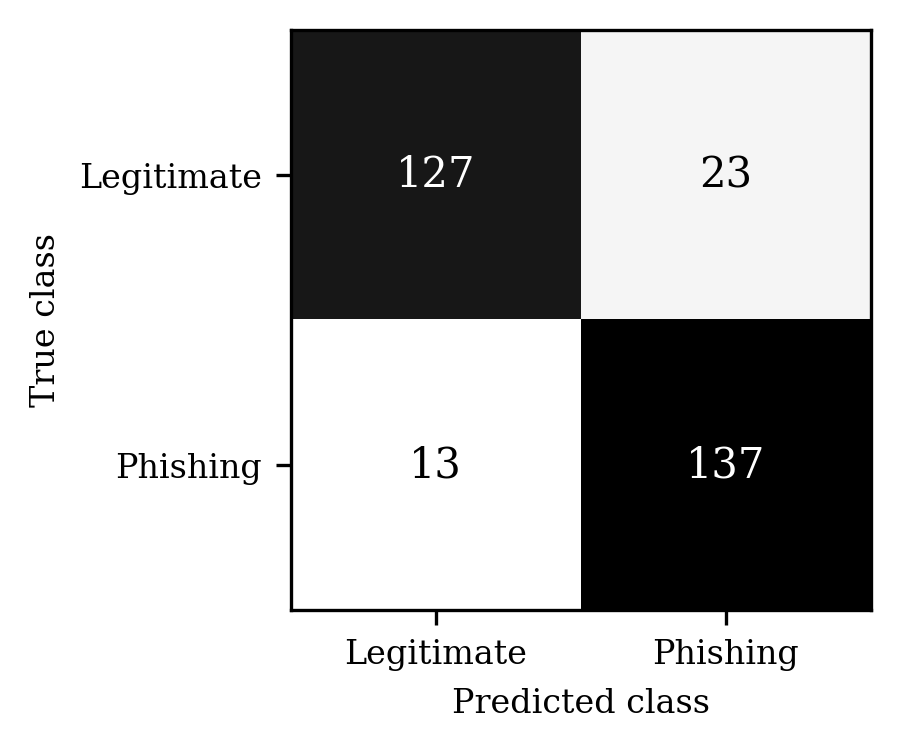

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# ===== Extra cell: numbers for Table II, Table VIII and Fig. 4 =====
# Paste this as a NEW cell at the very end of the notebook (after the benchmark cell)
# and run it once. It only uses variables that the notebook already creates.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# ---------- Table II : dataset sizes ----------
print('--- TABLE II ---')
print('candidate pool (merge + filter + dedup) :', len(df_all))
print('after label cleaning                    :', len(pool))
print('final balanced set                      :', len(df_raw))
print('train / validation / test               :', len(train_df), '/', len(val_df), '/', len(test_df))
print('augmented training set                  :', len(aug_train_df))
print('adversarial test set                    :', len(adv_test_df))
print('phishing URLs in test set               :', int((test_df.label == 1).sum()))

# ---------- Table VIII : recall per mutation type (M2, M3, M5) ----------
print('\n--- TABLE VIII (recall on mutated phishing URLs) ---')
urls_adv = adv_test_df['url'].tolist()
probs = {name: fn(urls_adv) for name, fn in [('M2', pred_m2), ('M3', pred_m3), ('M5', pred_m5)]}
rows = []
for t in ['homoglyph', 'subdomain', 'typosquatting', 'padding', 'encoding']:
    m = (adv_test_df['technique'] == t).values
    row = {'Mutation': t, 'URLs': int(m.sum())}
    for name, p in probs.items():
        row[name] = round(float((np.asarray(p)[m] >= 0.5).mean()), 2) if m.sum() else float('nan')
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

# ---------- Fig. 4 : confusion matrix of M5 on the adversarial test set ----------
y_true = adv_test_df['label'].values
y_hat = (np.asarray(probs['M5']) >= 0.5).astype(int)
cm = confusion_matrix(y_true, y_hat, labels=[0, 1])
print('\n--- FIG. 4 ---')
print('confusion matrix [[TN, FP], [FN, TP]] =', cm.tolist())

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(3.3, 2.6), dpi=300)
ax.imshow(cm, cmap='Greys')
names = ['Legitimate', 'Phishing']
ax.set_xticks([0, 1]); ax.set_xticklabels(names, fontsize=8)
ax.set_yticks([0, 1]); ax.set_yticklabels(names, fontsize=8)
ax.set_xlabel('Predicted class', fontsize=8); ax.set_ylabel('True class', fontsize=8)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=10,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.savefig('fig4_confusion_m5.png')
plt.show()
try:
    from google.colab import files
    files.download('fig4_confusion_m5.png')   # downloads the figure to your laptop
except Exception:
    pass

## Added M4 evaluation and paper table export

M4 is newly implemented as **M3 + retrieval-score adjustment only**, using the same 0.35 base-score gate and capped 0.20 retrieval boost already used in M5. It excludes M5's whitelist, evasion, IP-host and suspicious-TLD rules. This is a retrieval-assisted classifier, not an LLM-generated decision. The threshold remains 0.5. No M4 result is available until this cell runs.

**Existing Colab session:** run the cell below if Steps 1–10 have already run and their variables/models are still loaded. No retraining is needed in that session. **Fresh session:** run the notebook from the beginning; saved cell outputs do not restore trained models.

Other saved outputs are from the original run and are retained for reference. The revised Step 10 output is cleared because its old four-model table does not contain M4. This cell computes M4 on the current test sets and downloads its results and per-URL predictions. It does not produce or change any figure.


In [ ]:
# Standalone M4 evaluation: usable after the ORIGINAL Step 10 too.
import json
import numpy as np
import pandas as pd

required = ['model_3', 'get_probs', 'retrieve_context', 'evaluate', 'test_df', 'adv_test_df']
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Run the original notebook through Step 10 first. Missing: ' + ', '.join(missing))

def pred_m4(urls):
    """M3 + retrieval only: ablation of pred_m5 without whitelist/evasion/IP/TLD rules.

    Keep M5's existing base-score gate (0.35), retrieval weight (0.20),
    and upper cap. These are fixed inherited heuristics, not tuned here.
    Retrieval adjusts the classifier score; no LLM generates this score.
    """
    base = get_probs(model_3, urls)
    out = []
    for u, p in zip(urls, base):
        hits = retrieve_context(u, top_k=1)
        rel = hits[0]['relevance'] if hits else 0
        rag_boost = min(0.20, rel * 0.20)
        if float(p) >= 0.35:
            out.append(float(min(1.0, float(p) + rag_boost)))
        else:
            out.append(float(p))
    return np.array(out)

# Save the exact prediction vectors used by evaluate(), without extra model passes.
m4_vectors = []
def _record_m4(urls):
    scores = pred_m4(urls)
    m4_vectors.append(scores.copy())
    return scores

m4_result = evaluate(_record_m4)
if isinstance(globals().get('results'), dict):
    results['M4: M3 + Retrieval'] = m4_result
c, a = m4_result['clean'], m4_result['adv']
m4_table = pd.DataFrame([{
    'Model': 'M4: M3 + RAG',
    'Clean Acc.': f"{c['accuracy']:.2f}%",
    'Clean F1': f"{c['f1']:.4f}",
    'Adv. Acc.': f"{a['accuracy']:.2f}%",
    'Adv. F1': f"{a['f1']:.4f}",
    'F1 Drop': f"{m4_result['f1_drop']:.4f}",
}])
print('M4 RESULTS — copy this row into Table VII')
print(m4_table.to_string(index=False))
m4_table.to_csv('M4_table_results.csv', index=False)
with open('M4_metrics.json', 'w') as f:
    json.dump({'definition': pred_m4.__doc__, 'threshold': 0.5,
               'clean_n': len(test_df), 'adversarial_n': len(adv_test_df),
               'metrics': m4_result}, f, indent=2)
for label, frame, scores in zip(['clean', 'adversarial'], [test_df, adv_test_df], m4_vectors):
    exported = frame[['url', 'label']].copy()
    exported['m4_score'] = scores
    exported['m4_prediction'] = (scores >= 0.5).astype(int)
    exported.to_csv('M4_' + label + '_predictions.csv', index=False)

import zipfile
with zipfile.ZipFile('M4_results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for path in ['M4_table_results.csv', 'M4_metrics.json',
                 'M4_clean_predictions.csv', 'M4_adversarial_predictions.csv']:
        z.write(path)
try:
    from google.colab import files
except ImportError:
    print('Saved M4_results.zip in the current working directory.')
else:
    files.download('M4_results.zip')


## 🎉 Done!

### Performance Optimizations Applied:
1. ✅ Reduced dataset size (1000 vs 5000 samples)
2. ✅ Fewer training epochs (2 vs 3)
3. ✅ Smaller batch sizes (8 vs 16)
4. ✅ Progress bars for visibility
5. ✅ Optional label cleaning (disabled by default)
6. ✅ LRU caching for RAG retrieval
7. ✅ Simplified evaluation

### Expected Speedup:
- **Dataset loading:** ~2-5 minutes (cached after first run)
- **Training (CPU):** ~15-20 minutes (vs 45-60 minutes original)
- **Training (GPU):** ~3-5 minutes (vs 10-15 minutes original)
- **Total runtime:** **3-5x faster**

### To Speed Up Further:
- Set `MAX_PER_CLASS = 500` for even faster testing
- Set `TRAIN_EPOCHS = 1` for quick prototyping
- Enable GPU in Colab for massive speedup